In [1]:
from StochasticCliffWalking import StochasticCliffWalkingEnv
from tqdm import tqdm
from matplotlib.patches import Patch

import matplotlib.pyplot as plt
import numpy as np

In [2]:
env = StochasticCliffWalkingEnv()

In [36]:
# def epsilon_greedy_policy(nA, epsilon):
#     def policy(Q, state):
#         if np.random.random() < epsilon:
#             return np.random.randint(nA)
#         else:
#             return np.argmax(Q[state])
#     return policy

def epsilon_soft_policy(nA, epsilon=0.1):
    def policy(Q, state):
        action_probilities = np.full(nA, epsilon/nA)
        action_probilities[np.argmax(Q[state])] += 1 - epsilon
        return action_probilities
    return policy

In [38]:
def SARSA(env, episodes = 5000, gamma = 0.99, alpha = 0.1, epsilon=0.1):
    Q = np.zeros((env.nS, env.nA))

    policy = epsilon_soft_policy(env.nA, epsilon)

    episode_returns = []

    for _ in tqdm(range(episodes)):
        state, _ = env.reset()
        actions_prob = policy(Q, state)
        action = np.random.choice(len(actions_prob), p=actions_prob)
        total_reward = 0
        episode_done = False

        while not episode_done:
            next_state, reward, terminated, truncated, _ = env.step(action)

            episode_done = terminated or truncated
        
            if episode_done:
                Q[state, action] += alpha * (reward - Q[state, action])
                next_action = action
            else:
                next_actions_prob = policy(Q, state)
                next_action = np.random.choice(len(next_actions_prob), p=next_actions_prob)
                Q[state, action] += alpha * (reward + gamma * Q[next_state, next_action] - Q[state, action])
            
            state = next_state
            action = next_action
            total_reward += reward
        
        episode_returns.append(total_reward)
        
    return Q, episode_returns, []

# SARSA_q_best_history is for reusing code in multiple run function
SARSA_Q, SARSA_returns, SARSA_start_best_history = SARSA(env)

100%|██████████| 5000/5000 [00:11<00:00, 422.66it/s]


In [39]:
SARSA_Q[36]

array([ -50.62960285,  -64.09954653, -143.35971712,  -37.93519021])

In [40]:
def QLearning(env, episodes = 5000, gamma = 0.99, alpha = 0.1, epsilon=0.1):
    Q = np.zeros((env.nS, env.nA))

    episode_returns = []
    start_state = 36
    q_start_best_history = []

    policy = epsilon_soft_policy(env.nA, epsilon = epsilon)

    for _ in tqdm(range(episodes)):
        state, _ = env.reset()
        total_reward = 0
        episode_done = False

        while not episode_done:
            actions_prob = policy(Q, state)
            action = np.random.choice(len(actions_prob), p=actions_prob)
            
            next_state, reward, terminated, truncated, _ = env.step(action)

            episode_done = terminated or truncated
        
            if episode_done:
                Q[state, action] += alpha * (reward - Q[state, action])
            else:
                Q[state, action] += alpha * (reward + gamma * np.max(Q[next_state]) - Q[state, action])
            
            state = next_state
            total_reward += reward
        
        episode_returns.append(total_reward)

        q_start_best_value = np.max(Q[start_state])
        q_start_best_history.append(q_start_best_value)

    return Q, episode_returns, q_start_best_history

QLearning_Q, QLearning_returns, QLearning_start_history = QLearning(env)

100%|██████████| 5000/5000 [00:06<00:00, 805.67it/s]


In [41]:
def run_multiple_times(env, algorithm, runs = 10):
    all_Q = []
    all_returns = []
    all_start_best = []

    for _ in range(runs):
        Q, returns, start_history = algorithm(env)

        all_Q.append(Q)
        all_returns.append(returns)
        all_start_best.append(start_history)
    
    mean_returns = np.mean(all_returns, axis=0)
    std_returns = np.std(all_returns, axis=0)
    mean_Q = np.mean(all_Q, axis=0)
    mean_best_start = np.mean(all_start_best, axis=0)

    return mean_returns, std_returns, mean_Q, mean_best_start

SARSA_mean, SARSA_std, SARSA_Q, SARSA_start_val = run_multiple_times(env, SARSA)
QLearning_mean, QLearning_std, QLearning_Q, QLearning_start_val = run_multiple_times(env, QLearning)

  0%|          | 0/5000 [00:00<?, ?it/s]

100%|██████████| 5000/5000 [00:05<00:00, 900.30it/s] 


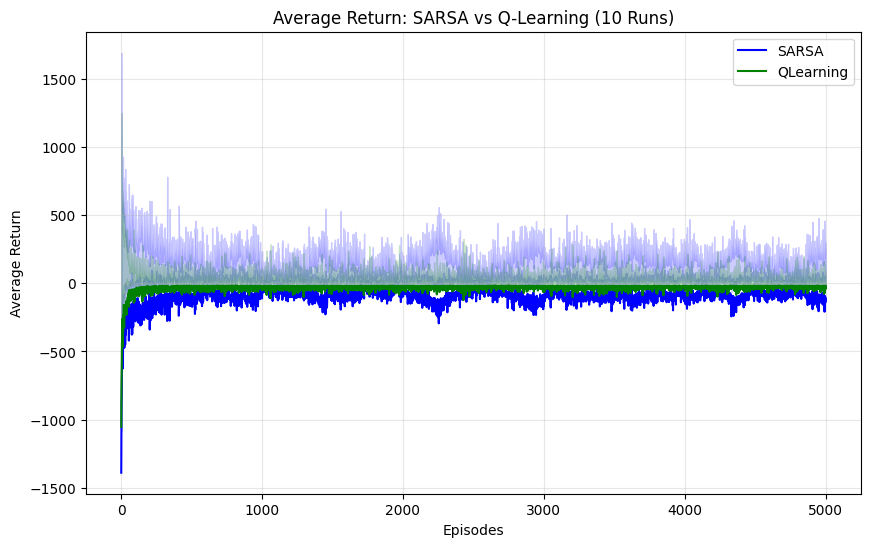

In [42]:
def plot_mean_std(mean_std_values, title, episodes, name):
    episodes = np.arange(1,episodes+1)

    plt.figure(figsize=(10, 6))
    for mean_val, std_val, color, label in mean_std_values:
        plt.plot(episodes, mean_val, label=label, color=color)
        plt.fill_between(episodes, std_val - mean_val, std_val + mean_val, color=color, alpha=0.2)

    plt.title(title)
    plt.xlabel('Episodes')
    plt.ylabel('Average Return')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.savefig(name)
    plt.show()

mean_std_values = [
    (SARSA_mean, SARSA_std, 'blue', 'SARSA'),
    (QLearning_mean, QLearning_std, 'green', 'QLearning'),
]

plot_mean_std(mean_std_values, 'Average Return: SARSA vs Q-Learning (10 Runs)', 5000, "homework-3-1")

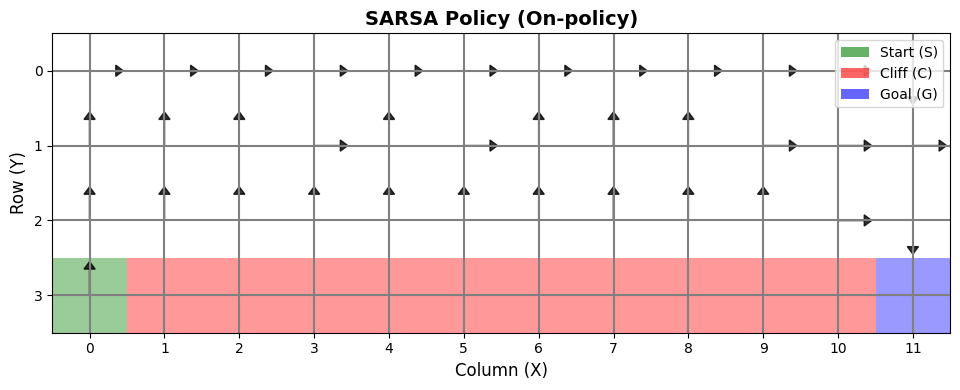

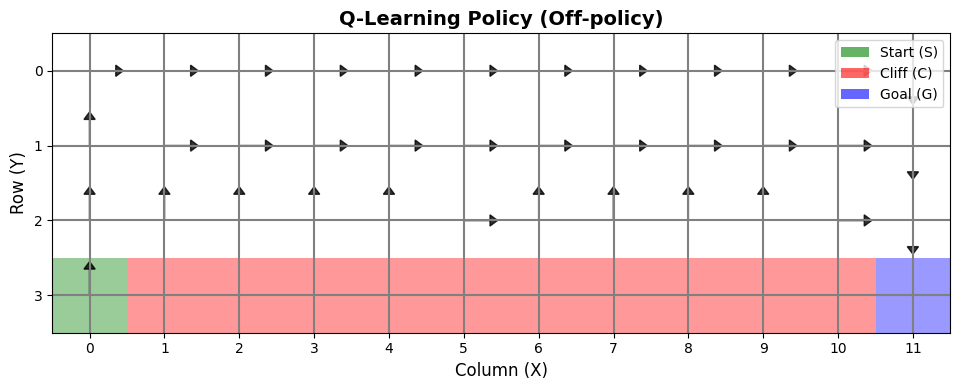

In [43]:
def visualize_policy(Q, title="Learned Policy", name="homework-3.png"):
    fig, ax = plt.subplots(figsize=(12, 4))
    
    grid_colors = np.zeros((4, 12))
    
    for state in range(48):
        row, col = divmod(state, 12)
        if 37 <= state <= 46:
            grid_colors[row, col] = 1
        elif state == 36:
            grid_colors[row, col] = 2
        elif state == 47:
            grid_colors[row, col] = 3
            
    cmap = plt.cm.colors.ListedColormap(['white', 'red', 'green', 'blue'])
    ax.imshow(grid_colors, cmap=cmap, alpha=0.4, extent=[-0.5, 11.5, 3.5, -0.5])
    
    for state in range(48):
        row, col = divmod(state, 12)
        
        if 37 <= state <= 46 or state == 47:
            continue
            
        best_action = np.argmax(Q[state])
        
        if best_action == 0:
            dx, dy = -0.35, 0
        elif best_action == 1:
            dx, dy = 0, 0.35
        elif best_action == 2:
            dx, dy = 0.35, 0
        elif best_action == 3:
            dx, dy = 0, -0.35
            
        ax.arrow(col, row, dx, dy, head_width=0.15, head_length=0.1, 
                 fc='black', ec='black', alpha=0.8)
        
    ax.set_xticks(np.arange(12))
    ax.set_yticks(np.arange(4))
    ax.set_xlim(-0.5, 11.5)
    ax.set_ylim(3.5, -0.5)
    ax.set_title(title, fontsize=14, fontweight='bold')
    ax.set_xlabel("Column (X)", fontsize=12)
    ax.set_ylabel("Row (Y)", fontsize=12)
    
    legend_elements = [
        Patch(facecolor='green', alpha=0.6, label='Start (S)'),
        Patch(facecolor='red', alpha=0.6, label='Cliff (C)'),
        Patch(facecolor='blue', alpha=0.6, label='Goal (G)')
    ]
    ax.legend(handles=legend_elements, loc='upper right', fontsize=10)
    
    ax.grid(True, which='both', color='gray', linestyle='-', linewidth=1.5)
    plt.tight_layout()
    plt.savefig(name)
    plt.show()

visualize_policy(SARSA_Q, title="SARSA Policy (On-policy)", name="homework-3-2.png")
visualize_policy(QLearning_Q, title="Q-Learning Policy (Off-policy)",name="homework-3-3.png")

In [44]:
def expected_SARSA(env, episodes=5000, alpha=0.1, gamma=0.99, epsilon=0.1):
    Q = np.zeros((env.nS, env.nA))

    policy = epsilon_soft_policy(env.nA, epsilon)

    episode_returns = []

    for _ in tqdm(range(episodes)):
        state, _ = env.reset()

        total_reward = 0
        episode_done = False

        while not episode_done:
            action_probs = policy(Q, state)
            action = np.random.choice(len(action_probs), p=action_probs)

            next_state, reward, terminated, truncated, _ = env.step(action)

            episode_done = terminated or truncated
        
            if episode_done:
                Q[state, action] += alpha * (reward - Q[state, action])
            else:
                next_action_probs = policy(Q, next_state)
                expected_val = np.sum(next_action_probs * Q[next_state])
                Q[state, action] += alpha * (reward + gamma * expected_val - Q[state, action])
            
            state = next_state
            total_reward += reward

        episode_returns.append(total_reward)

    return Q, episode_returns, []

expected_SARSA_Q, expected_SARSA_returns, expected_SARSA_start_his = expected_SARSA(env)

  0%|          | 0/5000 [00:00<?, ?it/s]

100%|██████████| 5000/5000 [00:07<00:00, 706.73it/s]


100%|██████████| 5000/5000 [00:06<00:00, 766.31it/s]


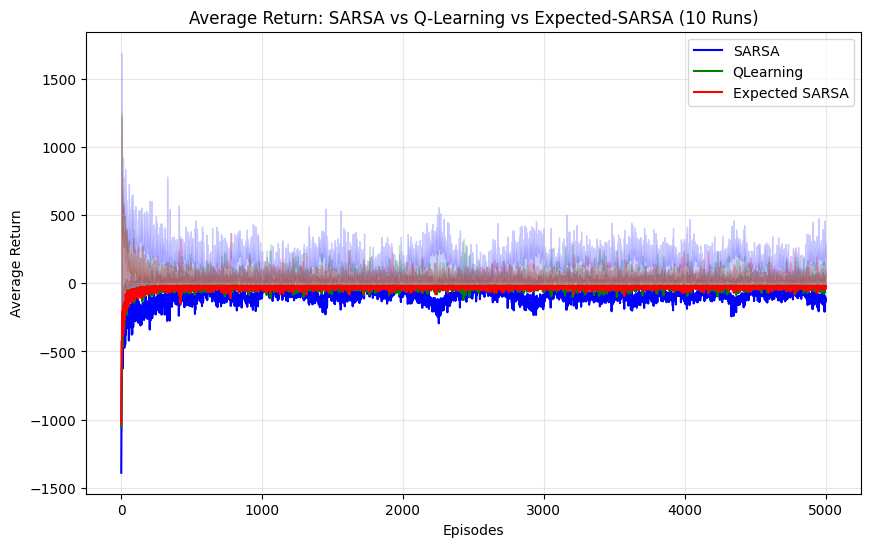

In [45]:
expected_SARSA_mean, expected_SARSA_std, expected_SARSA_Q, expected_SARSA_start_his = run_multiple_times(env, expected_SARSA)

mean_std_values = [
    (SARSA_mean, SARSA_std, 'blue', 'SARSA'),
    (QLearning_mean, QLearning_std, 'green', 'QLearning'),
    (expected_SARSA_mean, expected_SARSA_std, 'red', 'Expected SARSA')
]

plot_mean_std(mean_std_values, 'Average Return: SARSA vs Q-Learning vs Expected-SARSA (10 Runs)', 5000, "homework-3-4")

In [46]:
def double_QLearning(env, episodes = 5000, gamma = 0.99, alpha = 0.1, epsilon=0.1):
    Q1 = np.zeros((env.nS, env.nA))
    Q2 = np.zeros((env.nS, env.nA))

    episode_returns = []
    start_state = 36
    q_start_best_history = []

    policy = epsilon_soft_policy(env.nA, epsilon)

    for _ in tqdm(range(episodes)):
        state, _ = env.reset()
        total_reward = 0
        episode_done = False

        while not episode_done:
            Q = Q1 + Q2
            actions_prob = policy(Q, state)
            action = np.random.choice(len(actions_prob), p=actions_prob)
            next_state, reward, terminated, truncated, _ = env.step(action)

            episode_done = terminated or truncated

            if np.random.random() < 0.5:
                if episode_done:
                    Q1[state, action] += alpha * (reward - Q1[state, action])
                else:
                    Q1[state, action] += alpha * (reward + 
                                                  gamma * Q2[next_state, np.argmax(Q1[next_state])] - Q1[state, action])
            
            else:
                if episode_done:
                    Q2[state, action] += alpha * (reward - Q2[state, action])
                else:
                    Q2[state, action] += alpha * (reward + 
                                                  gamma * Q1[next_state, np.argmax(Q2[next_state])] - Q2[state, action])
            
            state = next_state
            total_reward += reward
        
        episode_returns.append(total_reward)
        best_action_start = np.argmax(Q1[start_state] + Q2[start_state])
        estimated_q_start = (Q1[start_state, best_action_start] + Q2[start_state, best_action_start]) / 2
        q_start_best_history.append(estimated_q_start)
            
    return Q1, Q2, episode_returns, q_start_best_history

double_QLearning_Q1, double_QLearning_Q2, double_QLearning_returns, start_state_best = double_QLearning(env)

  0%|          | 0/5000 [00:00<?, ?it/s]

100%|██████████| 5000/5000 [00:06<00:00, 757.27it/s]


100%|██████████| 5000/5000 [00:08<00:00, 610.91it/s]


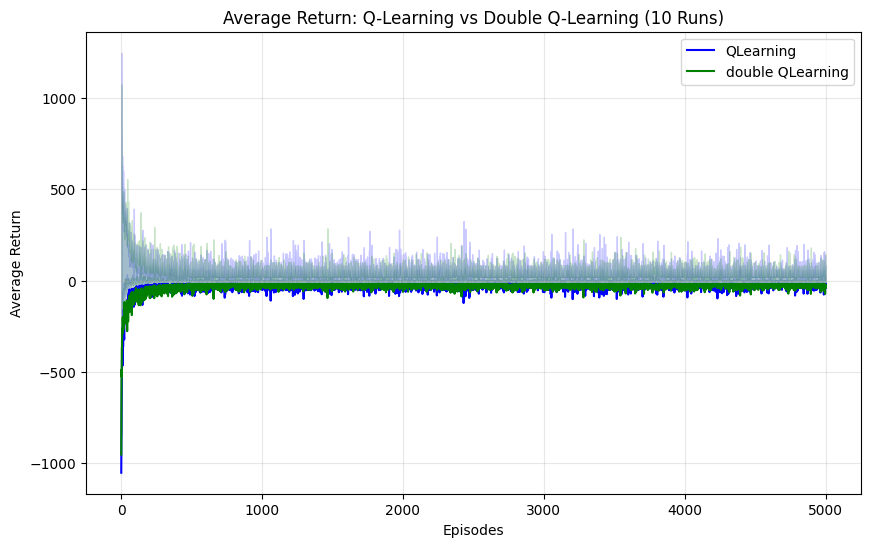

In [48]:
runs = 10

all_returns = []
all_start_values = []

for r in range(runs):
    double_QLearning_Q1, double_QLearning_Q2, double_QLearning_returns, start_state_best = double_QLearning(env)

    all_returns.append(double_QLearning_returns)
    all_start_values.append(start_state_best)

double_QLearning_mean_returns = np.mean(all_returns, axis=0)
double_QLearning_std_returns = np.std(all_returns, axis=0)
double_QLearning_start_best = np.mean(all_start_values, axis=0)


mean_std_values = [
    (QLearning_mean, QLearning_std, 'blue', 'QLearning'),
    (double_QLearning_mean_returns, double_QLearning_std_returns, 'green', 'double QLearning'),
]

plot_mean_std(mean_std_values, 'Average Return: Q-Learning vs Double Q-Learning (10 Runs)', 5000, "homework-3-5")

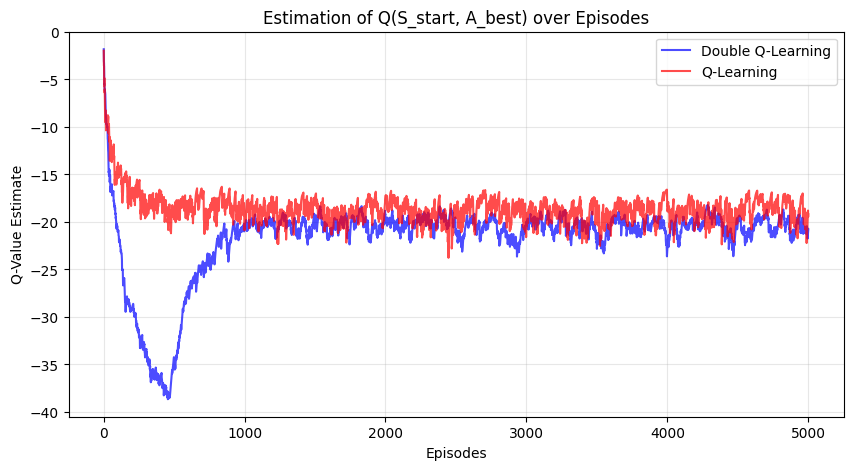

In [49]:
def run_and_plot_bias_comparison(double_QLearning_start_hist, QLearning_start_hist, episodes=5000):
    episodes = np.arange(1,episodes+1)

    plt.figure(figsize=(10, 5))
    plt.plot(episodes,double_QLearning_start_hist, label='Double Q-Learning', color='blue', alpha=0.7)
    plt.plot(episodes,QLearning_start_hist, label='Q-Learning', color='red', alpha=0.7)
    
    plt.title('Estimation of Q(S_start, A_best) over Episodes')
    plt.xlabel('Episodes')
    plt.ylabel('Q-Value Estimate')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.savefig("homework-3-6.png")
    plt.show()

run_and_plot_bias_comparison(double_QLearning_start_best, QLearning_start_val)